In [1]:
from read_pts import read_input_data

In [2]:
import pyvista as pv
import pandas as pd
import numpy as np
import open3d as o3d
from pyntcloud import PyntCloud
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
from scipy import interpolate

from skimage.measure import label
from skimage import data
from skimage import color
from skimage.morphology import extrema
from skimage import exposure

In [19]:
from PIL import Image

In [31]:
# data/External Scans/Citgo Tank 4- Setup 004.e57
path = "data/External Scans/txt"
src_filename = "Citgo Tank 4- Setup 005 - Cloud.e57"
src_points = read_input_data(path, src_filename)

In [34]:
x = src_points['x'].values
y = src_points['y'].values
z = src_points['z'].values
tank_pv = pv.PolyData(np.c_[x,y,z])
tank = PyntCloud.from_instance('pyvista', tank_pv)

n_x = int(960)
n_y = int(960)
n_z = 1
# voxelize
voxelgrid_id = tank.add_structure("voxelgrid", n_x=n_x, n_y=n_y, n_z=n_z)
voxelgrid = tank.structures[voxelgrid_id]

num_point = tank.points.shape[0]
den = voxelgrid.get_feature_vector('density')
cnt = den * num_point

# plt.figure(figsize=(12,12))
# plt.imshow(cnt[:,:,0] > 5000)

cnt_bin = np.uint8(cnt[:,:,0] > 5000)
# im = Image.fromarray(np.uint8(cnt_bin) * 255)
# im.putalpha(1)
# im.save('test.png')

In [44]:
im.save('test.png')

In [59]:
def visualise_tanks(data_dir, filename):
    src_points = read_input_data(data_dir, filename)
    x = src_points['x'].values
    y = src_points['y'].values
    z = src_points['z'].values
    tank_pv = pv.PolyData(np.c_[x,y,z])
    tank = PyntCloud.from_instance('pyvista', tank_pv)

    n_x = int(960)
    n_y = int(960)
    n_z = 1
    # voxelize
    voxelgrid_id = tank.add_structure("voxelgrid", n_x=n_x, n_y=n_y, n_z=n_z)
    voxelgrid = tank.structures[voxelgrid_id]

    num_point = tank.points.shape[0]
    den = voxelgrid.get_feature_vector('density')
    cnt = den * num_point

    plt.figure(figsize=(12,12))
    cnt_bin = np.uint8(cnt[:,:,0] < 5000) * 255
    plt.imshow(cnt_bin, cmap='gray')
    
    # cnt_bin = cnt[:,:,0] > 5000
    # im = Image.fromarray(np.uint8(cnt_bin) * 255)
    # im.putalpha(1)
    # im.save('test.png')
    plt.show()

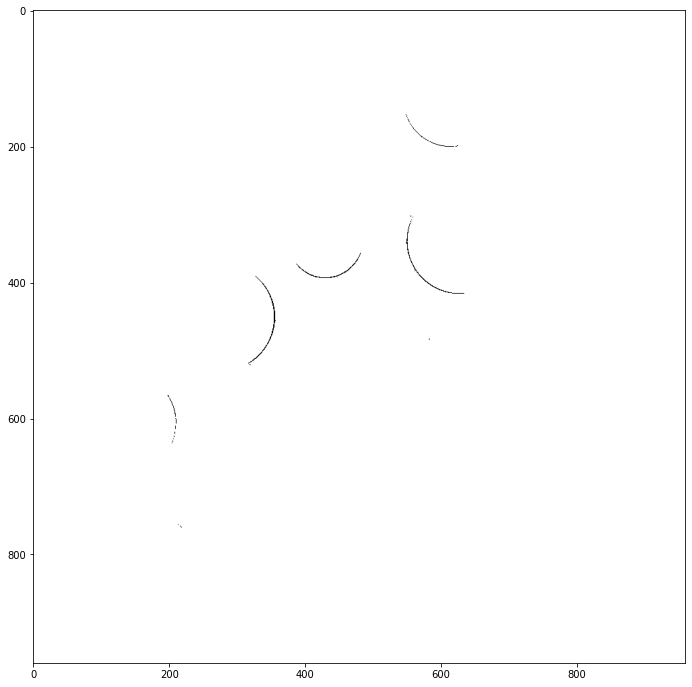

In [61]:
visualise_tanks(path, "Citgo Tank 4- Setup 004 - Cloud.e57")

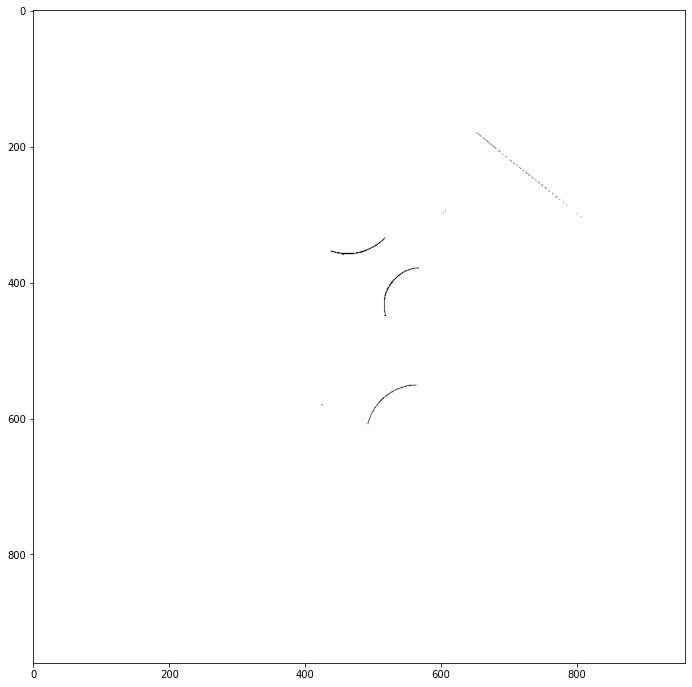

In [60]:
visualise_tanks(path, "Citgo Tank 4- Setup 005 - Cloud.e57")

In [6]:
type(src_points)

pandas.core.frame.DataFrame

In [7]:
src_points.head()

,x,y,z
0,16.991974,57.198261,-9.965470
1,16.992065,57.201954,-9.983538
2,16.991764,57.204750,-9.999662
3,16.501684,37.225521,-12.906837
4,16.938297,55.378437,-11.911297


In [10]:
x = src_points['x'].values
y = src_points['y'].values
z = src_points['z'].values
tank_pv = pv.PolyData(np.c_[x,y,z])

In [11]:
tank = PyntCloud.from_instance('pyvista', tank_pv)

In [12]:
n_x = int(960)
n_y = int(960)
n_z = 1
# voxelize
voxelgrid_id = tank.add_structure("voxelgrid", n_x=n_x, n_y=n_y, n_z=n_z)
voxelgrid = tank.structures[voxelgrid_id]

In [13]:
num_point = tank.points.shape[0]
den = voxelgrid.get_feature_vector('density')
cnt = den * num_point

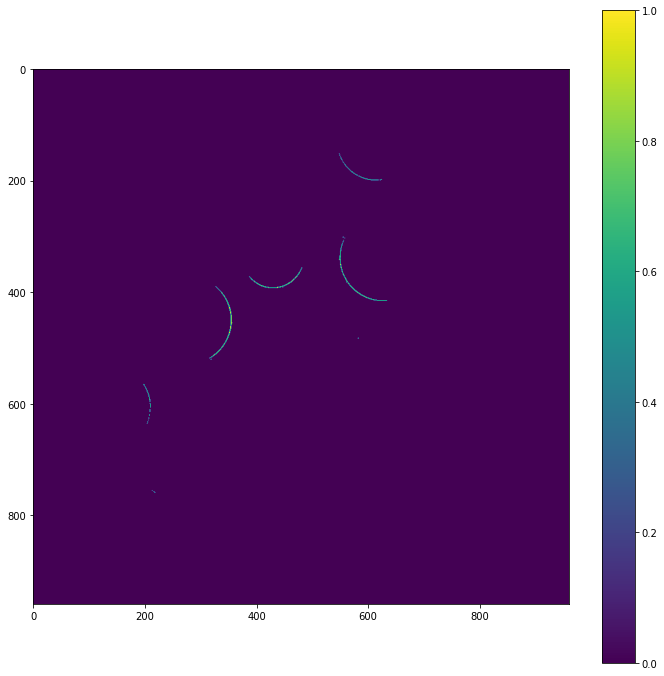

In [17]:
plt.figure(figsize=(12,12))
plt.imshow(cnt[:,:,0] > 5000)
plt.colorbar()
plt.show()

In [3]:
# a = np.array([[1+2j, 3+4j, 5+6j],[7+8j, 9+10j, 11+12j]])
a = np.array([[1+2j, 3+4j, -5+6j],[7+8j, 9-10j, 11+12j], [13+8j, 9+10j, 11+12j]])
a

array([[ 1. +2.j,  3. +4.j, -5. +6.j],
       [ 7. +8.j,  9.-10.j, 11.+12.j],
       [13. +8.j,  9.+10.j, 11.+12.j]])

In [4]:
imag = a.imag
real = a.real

In [5]:
np.stack([real, imag]).reshape(2,-1).transpose().reshape(-1,2*imag.shape[1])

array([[  1.,   2.,   3.,   4.,  -5.,   6.],
       [  7.,   8.,   9., -10.,  11.,  12.],
       [ 13.,   8.,   9.,  10.,  11.,  12.]])

In [9]:

from write_output import write_array2txt

In [10]:
write_array2txt('test.txt', a)

In [106]:
with open('test.txt', 'w') as f:
    f.write('s')